# ✈️ Airline Flight Analysis

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv('test.csv')

In [3]:
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied


In [4]:
df1 = pd.read_csv('train.csv')

In [5]:
df1.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [6]:
merged_df = pd.concat([df, df1], ignore_index=True)

print(merged_df.shape)
merged_df.head()

(129880, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied


In [7]:
print(df.shape)
print(df1.shape)

print(df.columns.equals(df1.columns))

(25976, 25)
(103904, 25)
True


In [8]:
merged_df.shape

(129880, 25)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   Gender                             25976 non-null  object 
 3   Customer Type                      25976 non-null  object 
 4   Age                                25976 non-null  int64  
 5   Type of Travel                     25976 non-null  object 
 6   Class                              25976 non-null  object 
 7   Flight Distance                    25976 non-null  int64  
 8   Inflight wifi service              25976 non-null  int64  
 9   Departure/Arrival time convenient  25976 non-null  int64  
 10  Ease of Online booking             25976 non-null  int64  
 11  Gate location                      25976 non-null  int

In [10]:
# removed the unnamed column
merged_df = df.drop(columns='Unnamed: 0')

In [11]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 24 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   id                                 25976 non-null  int64  
 1   Gender                             25976 non-null  object 
 2   Customer Type                      25976 non-null  object 
 3   Age                                25976 non-null  int64  
 4   Type of Travel                     25976 non-null  object 
 5   Class                              25976 non-null  object 
 6   Flight Distance                    25976 non-null  int64  
 7   Inflight wifi service              25976 non-null  int64  
 8   Departure/Arrival time convenient  25976 non-null  int64  
 9   Ease of Online booking             25976 non-null  int64  
 10  Gate location                      25976 non-null  int64  
 11  Food and drink                     25976 non-null  int

In [12]:
merged_df.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.00000,25893.000000
mean,65005.657992,39.620958,1193.788459,2.724746,3.046812,2.756775,2.977094,3.215353,3.261665,3.449222,3.357753,3.385664,3.350169,3.633238,3.314175,3.649253,3.286226,14.30609,14.740857
std,37611.526647,15.135685,998.683999,1.335384,1.533371,1.412951,1.282133,1.331506,1.355536,1.320090,1.338299,1.282088,1.318862,1.176525,1.269332,1.180681,1.319330,37.42316,37.517539
min,17.000000,7.000000,31.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.00000,0.000000
25%,32170.500000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.00000,0.000000
50%,65319.500000,40.000000,849.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.00000,0.000000
75%,97584.250000,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.00000,13.000000
max,129877.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1128.00000,1115.000000


In [13]:
merged_df.isnull().sum()
# in the arrival delay in minutes there are 393 null values

id                                    0
Gender                                0
Customer Type                         0
Age                                   0
Type of Travel                        0
Class                                 0
Flight Distance                       0
Inflight wifi service                 0
Departure/Arrival time convenient     0
Ease of Online booking                0
Gate location                         0
Food and drink                        0
Online boarding                       0
Seat comfort                          0
Inflight entertainment                0
On-board service                      0
Leg room service                      0
Baggage handling                      0
Checkin service                       0
Inflight service                      0
Cleanliness                           0
Departure Delay in Minutes            0
Arrival Delay in Minutes             83
satisfaction                          0
dtype: int64

In [14]:
# filled the missing values with mean
merged_df['Arrival Delay in Minutes'] = merged_df['Arrival Delay in Minutes'].fillna(merged_df['Arrival Delay in Minutes'].mean())

In [15]:
merged_df.isnull().sum()

id                                   0
Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

In [16]:
# no duplicate records
merged_df.duplicated().sum()

np.int64(0)

# exploratory data analysis (EDA)

In [23]:
df['satisfaction'].value_counts()

satisfaction
neutral or dissatisfied    14573
satisfied                  11403
Name: count, dtype: int64

In [26]:
# passenger satisfaction in percentage
print(df['satisfaction'].value_counts(normalize=True) * 100)

satisfaction
neutral or dissatisfied    56.101786
satisfied                  43.898214
Name: proportion, dtype: float64


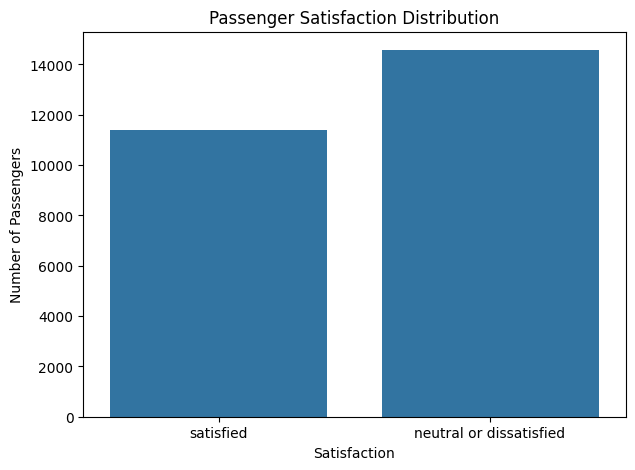

In [27]:
# count plot
plt.figure(figsize=(7, 5))

sns.countplot(data = merged_df, x='satisfaction')
plt.title('Passenger Satisfaction Distribution')
plt.xlabel('Satisfaction')
plt.ylabel('Number of Passengers')

plt.show()

In [29]:
# analyze age distribution
print(merged_df['Age'].describe())

count    25976.000000
mean        39.620958
std         15.135685
min          7.000000
25%         27.000000
50%         40.000000
75%         51.000000
max         85.000000
Name: Age, dtype: float64


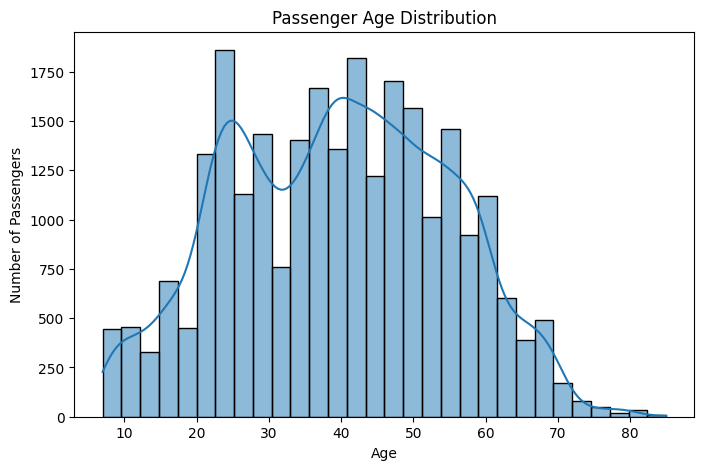

In [30]:
# histogram
plt.figure(figsize=(8, 5))

sns.histplot(data = merged_df, x='Age', bins= 30, kde= True)

plt.title('Passenger Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

Class
Business    12495
Eco         11564
Eco Plus     1917
Name: count, dtype: int64


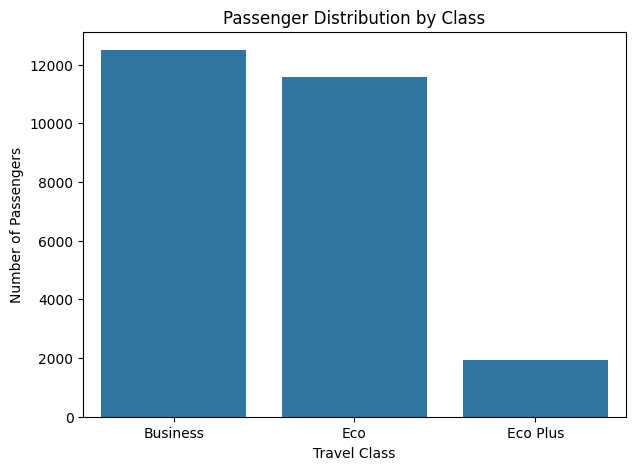

In [31]:
# Count passengers by class
print(df['Class'].value_counts())

# Create count plot
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Class', order=df['Class'].value_counts().index)

plt.title('Passenger Distribution by Class')
plt.xlabel('Travel Class')
plt.ylabel('Number of Passengers')

plt.show()

Type of Travel
Business travel    18038
Personal Travel     7938
Name: count, dtype: int64


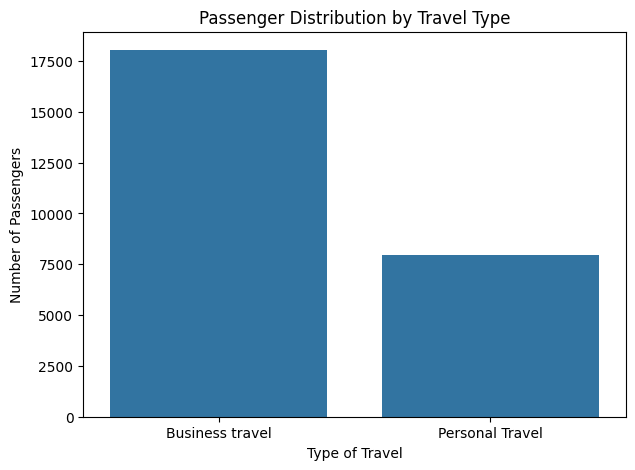

In [32]:
# Count travel types
print(df['Type of Travel'].value_counts())

# Create count plot
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Type of Travel')

plt.title('Passenger Distribution by Travel Type')
plt.xlabel('Type of Travel')
plt.ylabel('Number of Passengers')

plt.show()

In [34]:
print(df['Type of Travel'].value_counts())

Type of Travel
Business travel    18038
Personal Travel     7938
Name: count, dtype: int64


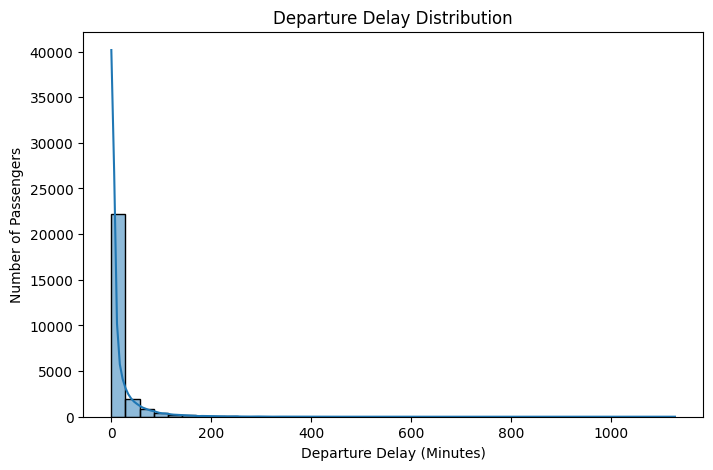

In [35]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Departure Delay in Minutes',
    bins=40,
    kde=True
)

plt.title('Departure Delay Distribution')
plt.xlabel('Departure Delay (Minutes)')
plt.ylabel('Number of Passengers')

plt.show()

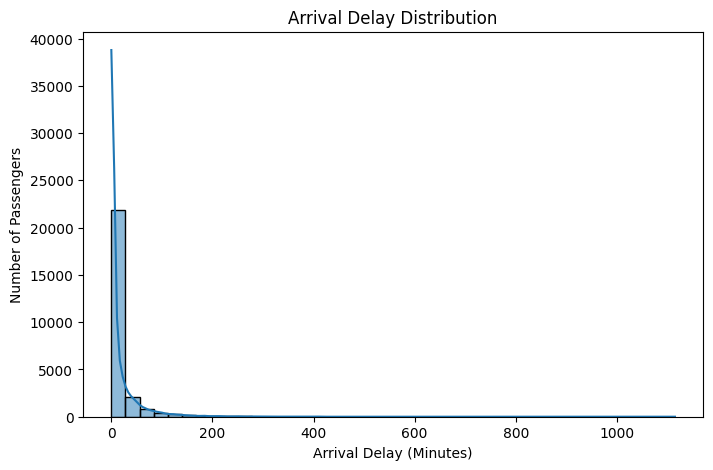

In [36]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Arrival Delay in Minutes',
    bins=40,
    kde=True
)

plt.title('Arrival Delay Distribution')
plt.xlabel('Arrival Delay (Minutes)')
plt.ylabel('Number of Passengers')

plt.show()

In [37]:
delay_data = df[
    ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
]

print(delay_data.describe())

       Departure Delay in Minutes  Arrival Delay in Minutes
count                 25976.00000              25893.000000
mean                     14.30609                 14.740857
std                      37.42316                 37.517539
min                       0.00000                  0.000000
25%                       0.00000                  0.000000
50%                       0.00000                  0.000000
75%                      12.00000                 13.000000
max                    1128.00000               1115.000000


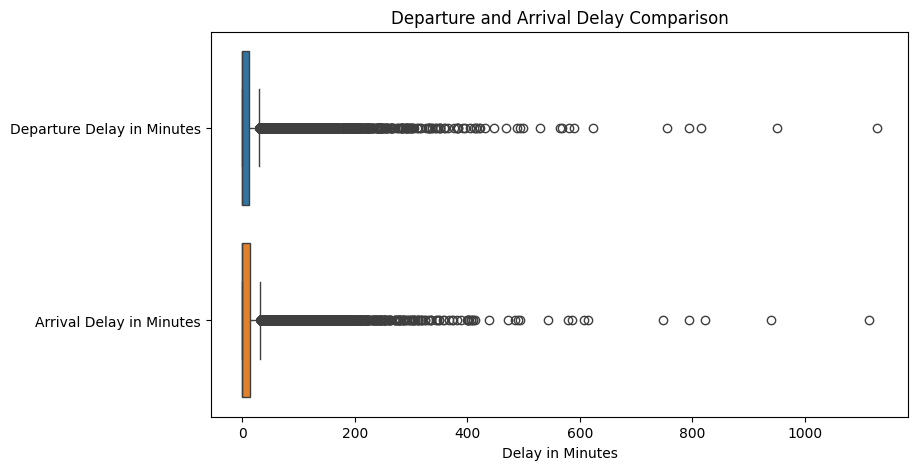

In [38]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=delay_data,
    orient='h'
)

plt.title('Departure and Arrival Delay Comparison')
plt.xlabel('Delay in Minutes')

plt.show()

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   Gender                             25976 non-null  object 
 3   Customer Type                      25976 non-null  object 
 4   Age                                25976 non-null  int64  
 5   Type of Travel                     25976 non-null  object 
 6   Class                              25976 non-null  object 
 7   Flight Distance                    25976 non-null  int64  
 8   Inflight wifi service              25976 non-null  int64  
 9   Departure/Arrival time convenient  25976 non-null  int64  
 10  Ease of Online booking             25976 non-null  int64  
 11  Gate location                      25976 non-null  int


Satisfaction by Class:
Class
Business    69.515806
Eco Plus    24.778299
Eco         19.387755
Name: satisfaction, dtype: float64


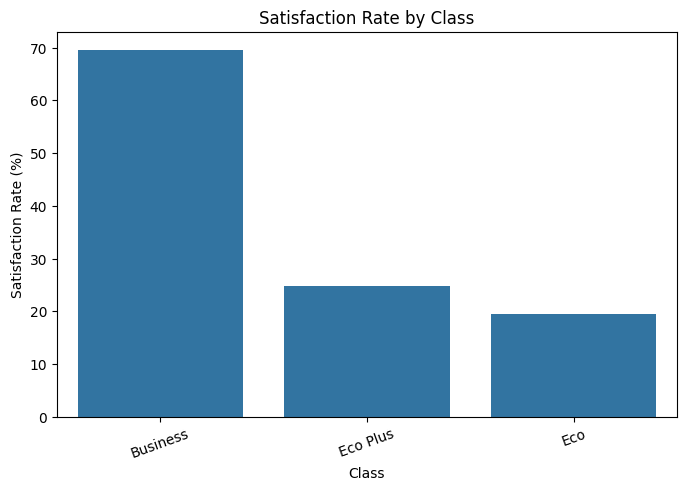


Satisfaction by Type of Travel:
Type of Travel
Business travel    58.820268
Personal Travel     9.989922
Name: satisfaction, dtype: float64


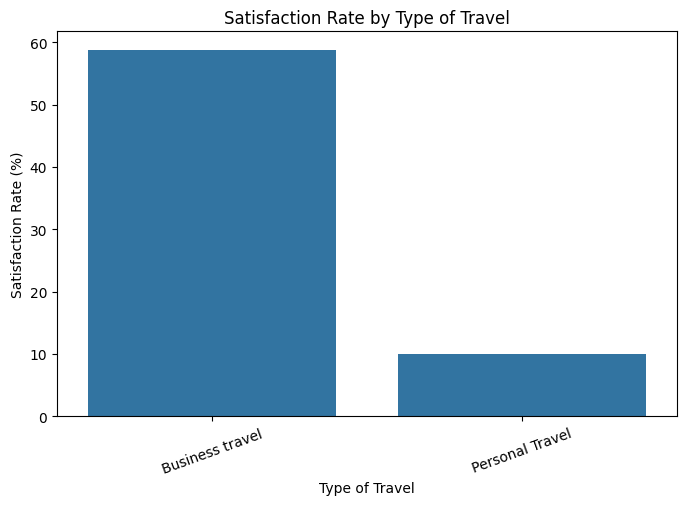


Satisfaction by Customer Type:
Customer Type
Loyal Customer       48.141852
disloyal Customer    25.171911
Name: satisfaction, dtype: float64


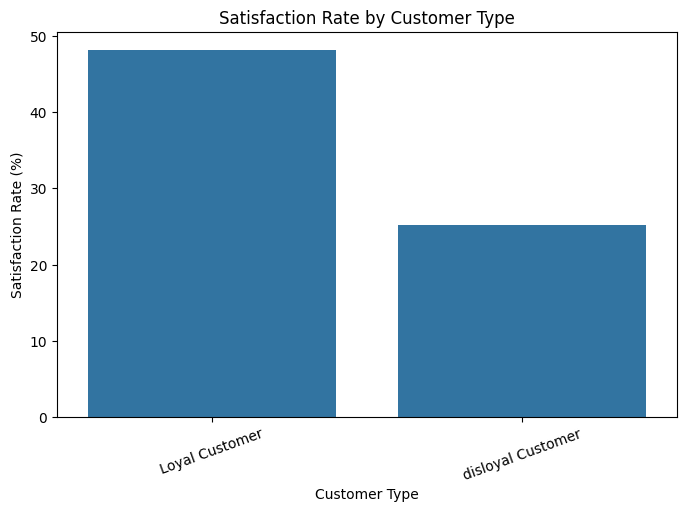


Satisfaction by Gender:
Gender
Male      44.267416
Female    43.539326
Name: satisfaction, dtype: float64


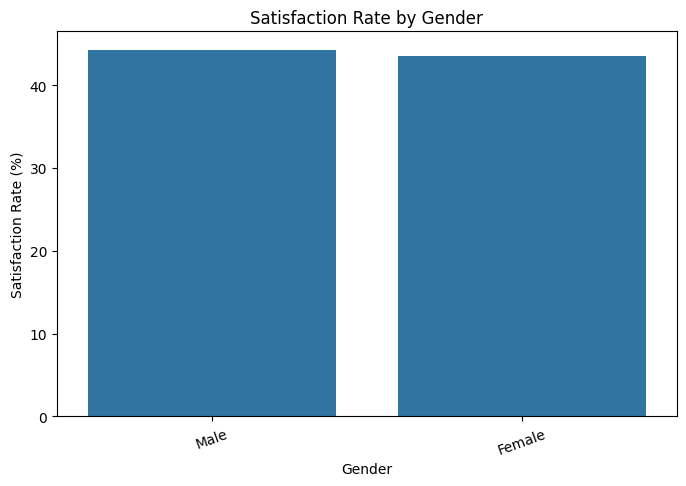

In [40]:
# most satisfied passenger group
categories = [
    'Class',
    'Type of Travel',
    'Customer Type',
    'Gender'
]

for col in categories:

    result = df.groupby(col)['satisfaction'].apply(
        lambda x: (x == 'satisfied').mean() * 100
    ).sort_values(ascending=False)

    print(f"\nSatisfaction by {col}:")
    print(result)

    plt.figure(figsize=(8, 5))

    sns.barplot(x=result.index, y=result.values)

    plt.title(f'Satisfaction Rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Satisfaction Rate (%)')
    plt.xticks(rotation=20)

    plt.show()

Average Service Ratings:
Inflight wifi service                2.724746
Ease of Online booking               2.756775
Departure/Arrival time convenient    3.046812
Food and drink                       3.215353
Online boarding                      3.261665
Cleanliness                          3.286226
Checkin service                      3.314175
Leg room service                     3.350169
Inflight entertainment               3.357753
On-board service                     3.385664
Seat comfort                         3.449222
Baggage handling                     3.633238
Inflight service                     3.649253
dtype: float64


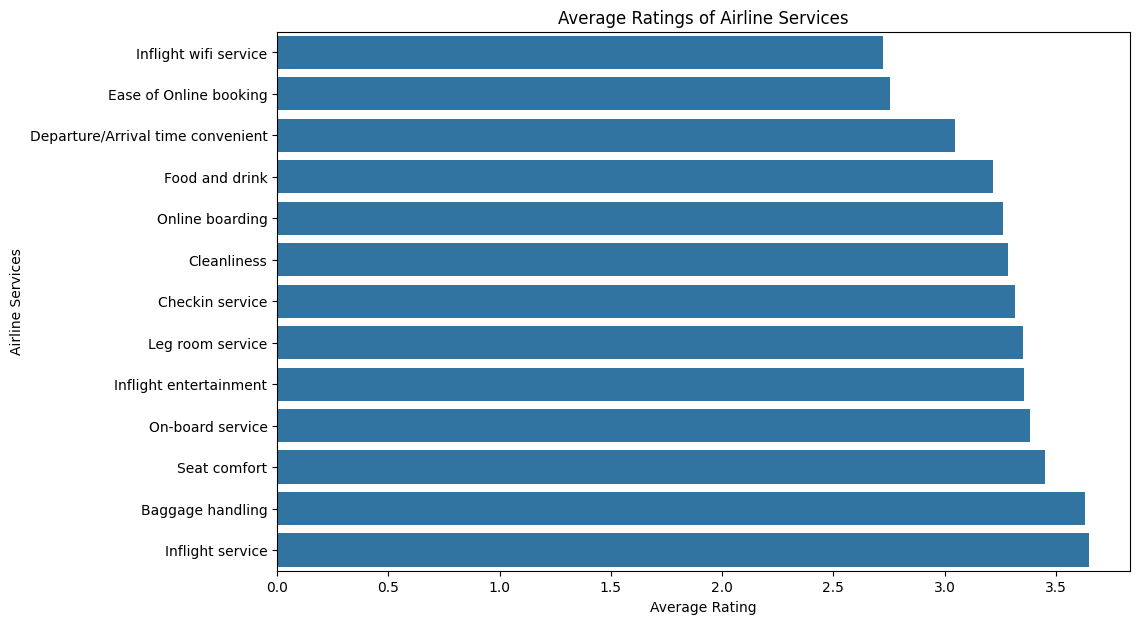

In [41]:
# least satisfactory airline services
service_columns = [
    'Inflight wifi service',
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Inflight service',
    'Cleanliness'
]

service_ratings = df[service_columns].mean().sort_values()

print("Average Service Ratings:")
print(service_ratings)

plt.figure(figsize=(11, 7))

sns.barplot(
    x=service_ratings.values,
    y=service_ratings.index
)

plt.title('Average Ratings of Airline Services')
plt.xlabel('Average Rating')
plt.ylabel('Airline Services')

plt.show()

Delay Category
No Delay            14688
1-15 Minutes         5603
16-30 Minutes        2116
31-60 Minutes        1833
Above 60 Minutes     1736
Name: count, dtype: int64


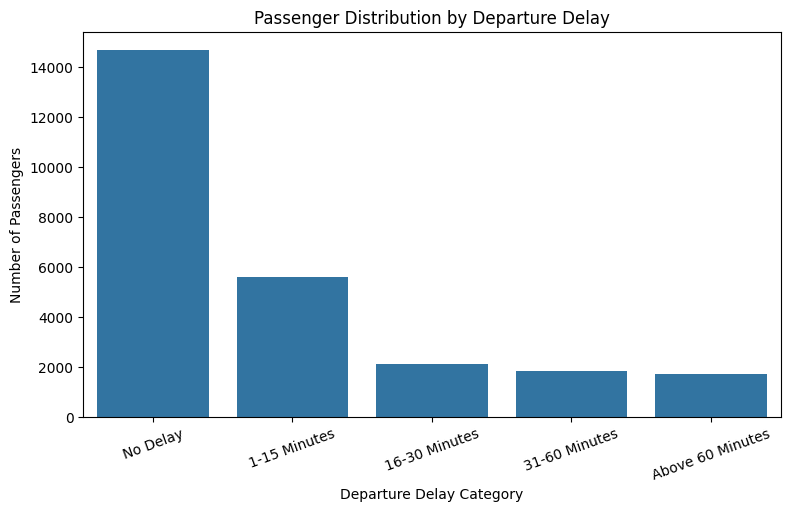

In [45]:
# flight delay patterns
df['Delay Category'] = pd.cut(
    df['Departure Delay in Minutes'],
    bins=[-1, 0, 15, 30, 60, float('inf')],
    labels=[
        'No Delay',
        '1-15 Minutes',
        '16-30 Minutes',
        '31-60 Minutes',
        'Above 60 Minutes'
    ]
)

print(df['Delay Category'].value_counts())

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Delay Category',
    order=[
        'No Delay',
        '1-15 Minutes',
        '16-30 Minutes',
        '31-60 Minutes',
        'Above 60 Minutes'
    ]
)

plt.title('Passenger Distribution by Departure Delay')
plt.xlabel('Departure Delay Category')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=20)

plt.show()

Delay Category
No Delay            46.684368
1-15 Minutes        43.101910
16-30 Minutes       39.177694
31-60 Minutes       36.606656
Above 60 Minutes    36.347926
Name: satisfaction, dtype: float64


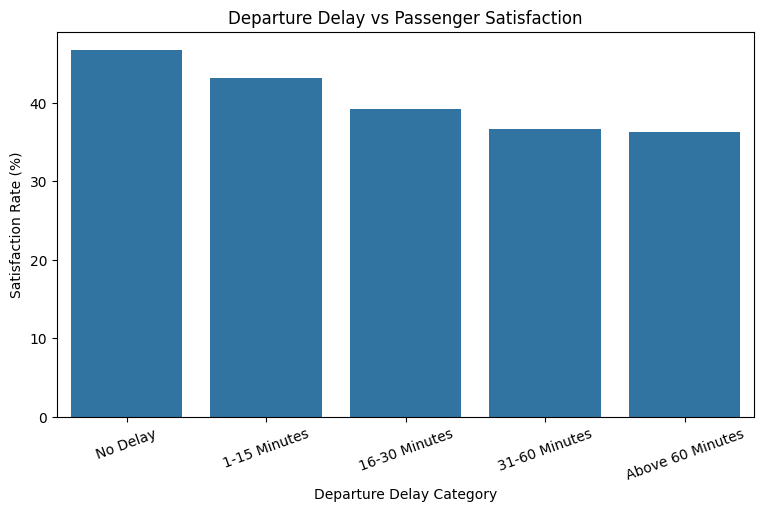

In [46]:
# analyze delay satisfaction
delay_satisfaction = df.groupby(
    'Delay Category',
    observed=False
)['satisfaction'].apply(
    lambda x: (x == 'satisfied').mean() * 100
)

print(delay_satisfaction)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=delay_satisfaction.index,
    y=delay_satisfaction.values
)

plt.title('Departure Delay vs Passenger Satisfaction')
plt.xlabel('Departure Delay Category')
plt.ylabel('Satisfaction Rate (%)')
plt.xticks(rotation=20)

plt.show()

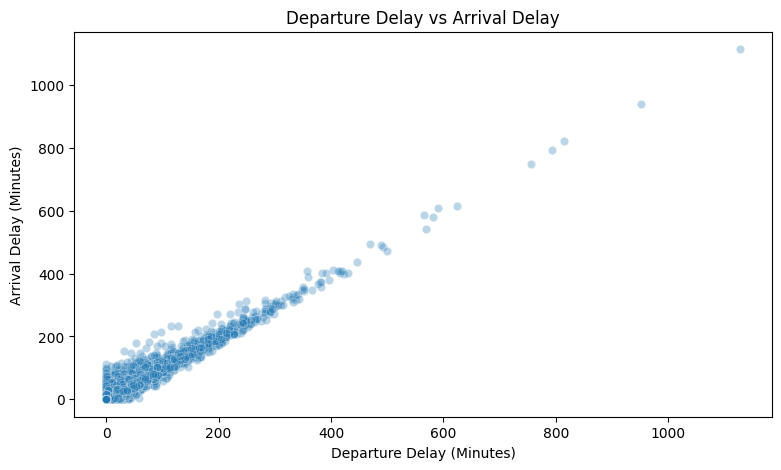

In [47]:
# departure and arrival delays
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Departure Delay in Minutes',
    y='Arrival Delay in Minutes',
    alpha=0.3
)

plt.title('Departure Delay vs Arrival Delay')
plt.xlabel('Departure Delay (Minutes)')
plt.ylabel('Arrival Delay (Minutes)')

plt.show()

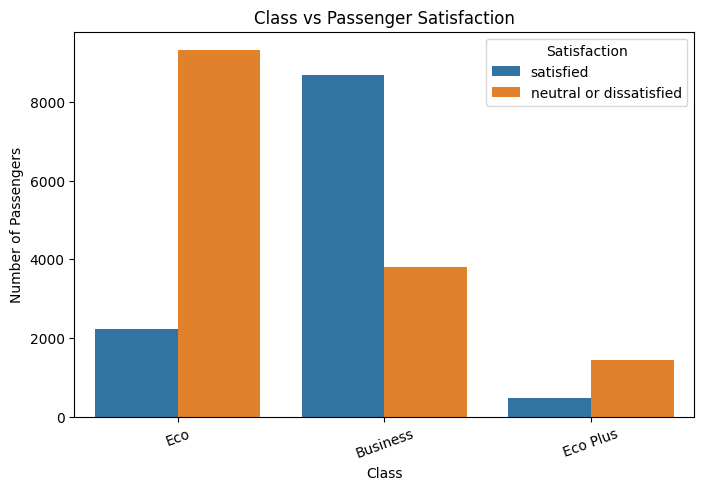

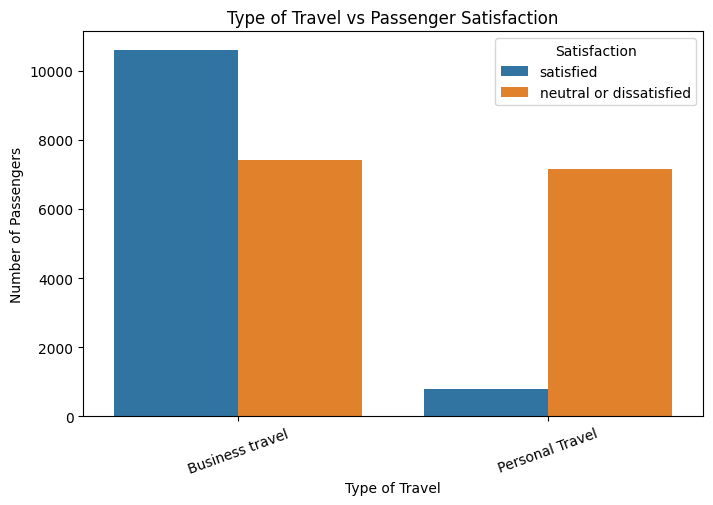

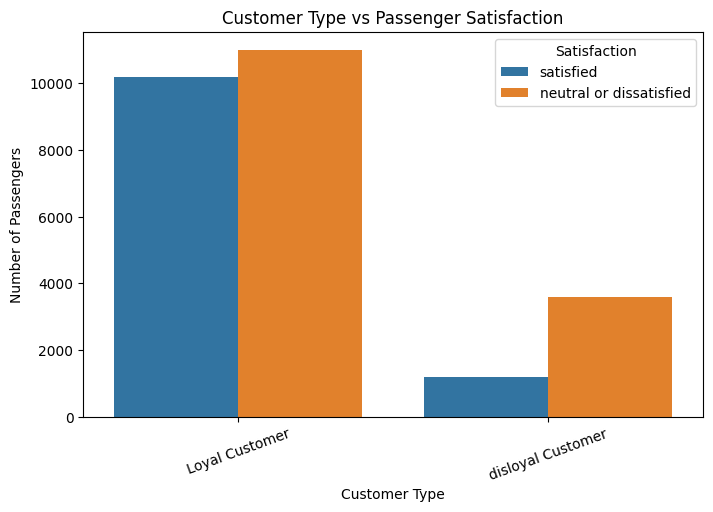

In [48]:
# satisfaction among different passenger categories
categories = [
    'Class',
    'Type of Travel',
    'Customer Type'
]

for col in categories:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=col,
        hue='satisfaction'
    )

    plt.title(f'{col} vs Passenger Satisfaction')
    plt.xlabel(col)
    plt.ylabel('Number of Passengers')
    plt.xticks(rotation=20)

    plt.legend(title='Satisfaction')

    plt.show()

In [49]:
for col in categories:

    result = pd.crosstab(
        df[col],
        df['satisfaction'],
        normalize='index'
    ) * 100

    print(f"\nSatisfaction Percentage by {col}:")
    print(result.round(2))


Satisfaction Percentage by Class:
satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                        30.48      69.52
Eco                             80.61      19.39
Eco Plus                        75.22      24.78

Satisfaction Percentage by Type of Travel:
satisfaction     neutral or dissatisfied  satisfied
Type of Travel                                     
Business travel                    41.18      58.82
Personal Travel                    90.01       9.99

Satisfaction Percentage by Customer Type:
satisfaction       neutral or dissatisfied  satisfied
Customer Type                                        
Loyal Customer                       51.86      48.14
disloyal Customer                    74.83      25.17


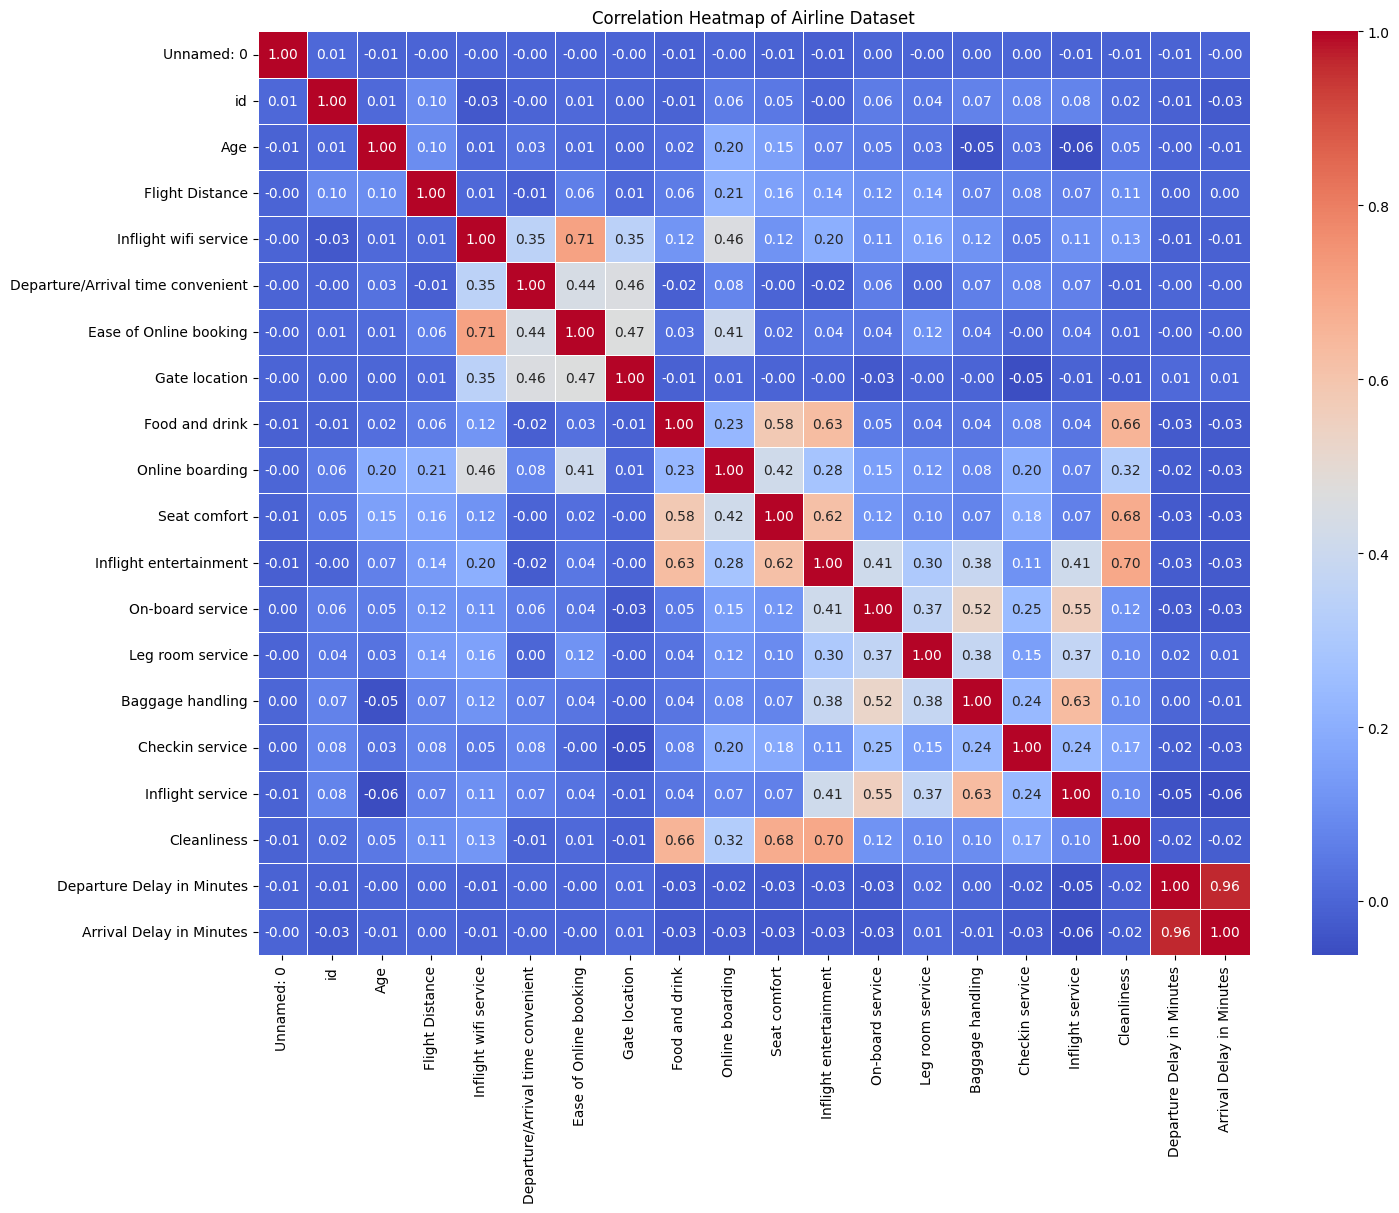

In [50]:
numeric_df = df.select_dtypes(include='number')

correlation = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Airline Dataset')

plt.show()